# 01 — Exploración inicial y limpieza de datos

**Objetivo:** cargar los datos, inspeccionarlos, detectar problemas de calidad con SQL y limpiarlos justificando cada decisión.

**Qué NO hace este notebook:** comparar a los clientes que abandonan con los que se quedan. Eso es el análisis estadístico del notebook 02, con las hipótesis fijadas de antemano en el [documento de diseño](../docs/01_project_design.md).

**Recorrido:**
1. CSV original
2. Base de datos "operativa" (capa `raw_*`)
3. Calidad con SQL
4. Decisiones de limpieza
5. Aplicar la limpieza
6. Tipos de datos
7. Outliers y sesgos
8. Verificación final
9. Resumen

> La lógica reutilizable vive en `src/` y las consultas en `sql/`. Este notebook las ejecuta y explica los resultados.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import config, viz
from src.build_database import build_database, load_source_csv, months_between
from src.data_cleaning import (
    clean_tables,
    load_raw_tables,
    quality_summary,
    run_quality_checks,
    write_clean_tables,
)
from src.database import get_connection, load_named_queries, query
from src.download_data import download_dataset

pd.set_option("display.max_columns", 25)
viz.apply_style()

## 1. El CSV original

Reconstruimos todo desde cero para que el notebook sea reproducible: descarga con verificación SHA-256 y creación de la base de datos. Tarda unos segundos.

In [2]:
download_dataset()
manifest = build_database()  # el manifiesto de defectos NO se usa para limpiar (solo lo usan los tests)

Dataset ya descargado y verificado: data\raw\Telco-Customer-Churn.csv


Base de datos creada: data\churn.db
  raw_customers         7,063 filas
  raw_subscriptions     7,043 filas
  raw_services         23,685 filas
  raw_payments        228,080 filas
Defectos inyectados: 200 (manifiesto: data\raw\injected_defects.csv)


### 1.1 Tamaño y primeras filas

Dejamos que pandas lea el fichero adivinando los tipos, como haría cualquiera en un primer vistazo.

In [3]:
source = pd.read_csv(config.RAW_CSV_PATH)
print(f"Filas: {source.shape[0]:,} · Columnas: {source.shape[1]}")
source.head()

Filas: 7,043 · Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Tipos de datos

In [4]:
source.dtypes.rename("tipo inferido").to_frame()

,tipo inferido
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


**Lectura:**

- **`TotalCharges` se lee como texto (`str`)**, aunque es un importe. Algún valor del fichero no es un número válido. Es un *tipo incorrecto* que hay que investigar.
- **`SeniorCitizen` es un entero 0/1**, mientras que el resto de variables sí/no vienen como texto `Yes`/`No`. No es un error, pero es una inconsistencia de formato. Lo unificaremos en SQL al construir la tabla final.

### 1.3 Valores nulos: `isna()` no lo cuenta todo

In [5]:
print("Nulos detectados por pandas:", int(source.isna().sum().sum()))

source_text = load_source_csv()  # todo como texto, sin interpretar nada
blank_counts = source_text.apply(lambda column: column.str.strip().eq("").sum())
blank_counts[blank_counts > 0].rename("valores en blanco").to_frame()

Nulos detectados por pandas: 0


,valores en blanco
TotalCharges,11


In [6]:
source_text.loc[source_text["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20,
5218,2923-ARZLG,0,19.7,
6670,4075-WKNIU,0,73.35,


**Lectura:** pandas no ve ningún nulo, pero **hay 11 `TotalCharges` vacíos** (contienen un espacio en blanco). Por eso la columna se leía como texto. Los 11 tienen `tenure = 0`: son clientes recién dados de alta que todavía no han recibido ninguna factura. No es un dato perdido al azar; el total real es 0 (decisión en la sección 4).

> **En sencillo:** que `isna()` diga 0 no garantiza que no falten datos. Hay que buscar también vacíos, espacios y valores "comodín".

### 1.4 Duplicados y categorías redundantes

In [7]:
print("Filas duplicadas exactas:", source.duplicated().sum())
print("customerID repetidos:   ", source["customerID"].duplicated().sum())
pd.crosstab(source["InternetService"], source["OnlineSecurity"])

Filas duplicadas exactas: 0
customerID repetidos:    0


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


**Lectura:**

- El CSV original **no tiene duplicados**.
- **"No internet service" es redundante:** aparece exactamente en los 1.526 clientes con `InternetService = No`. Lo mismo ocurre con "No phone service". En el modelo de datos esto se resuelve solo: la tabla `services` guarda únicamente los servicios contratados, y "sin internet" ya lo indica `internet_service`.

## 2. La base de datos "operativa" (capa `raw_*`)

El CSV se ha repartido en 4 tablas, como estarían en los sistemas de una empresa (ver [diseño §3](../docs/01_project_design.md)). La capa `raw_*` es la extracción tal cual llega: **sin restricciones** y con los defectos de calidad que inyectamos a propósito (documentados en el diseño, §3.6).

In [8]:
conn = get_connection()
query(conn, """
    SELECT 'raw_customers' AS tabla, COUNT(*) AS filas FROM raw_customers
    UNION ALL SELECT 'raw_subscriptions', COUNT(*) FROM raw_subscriptions
    UNION ALL SELECT 'raw_services', COUNT(*) FROM raw_services
    UNION ALL SELECT 'raw_payments', COUNT(*) FROM raw_payments
""")

,tabla,filas
0,raw_customers,7063
1,raw_subscriptions,7043
2,raw_services,23685
3,raw_payments,228080


In [9]:
display(query(conn, "SELECT * FROM raw_subscriptions LIMIT 3"))
display(query(conn, "SELECT * FROM raw_payments LIMIT 3"))

,customer_id,contract_type,internet_service,paperless_billing,payment_method,monthly_charges,total_charges,start_date,end_date
0,7590-VHVEG,Month-to-month,DSL,Yes,Electronic check,29.85,29.85,2024-09-01,NaN
1,5575-GNVDE,One year,DSL,No,Mailed check,56.95,1889.5,2021-12-01,NaN
2,3668-QPYBK,Month-to-month,DSL,Yes,Mailed check,53.85,108.15,2024-08-01,2024-10-01


,payment_id,customer_id,payment_date,amount
0,1,0017-IUDMW,2018-10-01,117.75
1,2,0019-EFAEP,2018-10-01,101.15
2,3,0078-XZMHT,2018-10-01,87.85


Una primera pista sin ejecutar ninguna regla: si cada cliente paga una factura por mes de antigüedad, el número esperado de pagos es la suma de las antigüedades. Lo calculamos con funciones de fecha de SQLite (diferencia en meses entre el alta y la fecha de corte).

In [10]:
query(conn, """
    SELECT SUM(
             (CAST(strftime('%Y', si.snapshot_date) AS INTEGER) - CAST(strftime('%Y', s.start_date) AS INTEGER)) * 12
           + (CAST(strftime('%m', si.snapshot_date) AS INTEGER) - CAST(strftime('%m', s.start_date) AS INTEGER))
           ) AS pagos_esperados,
           (SELECT COUNT(*) FROM raw_payments) AS pagos_en_tabla,
           (SELECT COUNT(*) FROM raw_customers) - (SELECT COUNT(DISTINCT customer_id) FROM raw_customers) AS filas_de_cliente_repetidas
    FROM raw_subscriptions AS s
    CROSS JOIN snapshot_info AS si
""")

,pagos_esperados,pagos_en_tabla,filas_de_cliente_repetidas
0,227990,228080,20


**Lectura:** sobran **90 pagos** respecto a lo esperado y hay **20 filas de cliente repetidas**. Algo no cuadra: las reglas de calidad tienen que explicar ambas diferencias.

## 3. Comprobaciones de calidad con SQL

Las reglas están en [`sql/01_data_quality.sql`](../sql/01_data_quality.sql). Cada consulta devuelve las **filas problemáticas**: 0 filas significa que la comprobación se supera.

In [11]:
checks = run_quality_checks(conn)
quality_summary(checks)

,check,rows_flagged
0,check_duplicate_customers,20
1,check_duplicate_subscriptions,0
2,check_duplicate_payments,50
3,check_conflicting_payments,0
4,check_missing_values,2
5,check_non_canonical_categories,23
6,check_impossible_values,0
7,check_monthly_charges_outliers,10
8,check_orphan_payments,30
9,check_unmatched_records,0


### 3.1 Duplicados

In [12]:
display(checks["check_duplicate_customers"].head())
print("Versiones distintas por cliente duplicado:", checks["check_duplicate_customers"]["n_versions"].unique())
checks["check_duplicate_payments"].head()

,customer_id,n_rows,n_versions
0,0128-MKWSG,2,1
1,0657-DOGUM,2,1
2,1599-EAHXY,2,1
3,1834-ABKHQ,2,1
4,1925-LFCZZ,2,1


Versiones distintas por cliente duplicado: [1]


,customer_id,payment_date,amount,n_rows,first_payment_id,last_payment_id
0,0623-EJQEG,2021-12-01,93.37,2,71966,228017
1,0772-GYEQQ,2024-07-01,86.85,2,208830,228004
2,0823-HSCDJ,2021-11-01,49.05,2,68885,228023
3,1187-WILMM,2024-01-01,88.84,2,175231,228037
4,1207-BLKSA,2023-08-01,24.16,2,150328,228056


**Lectura:**

- **20 clientes aparecen dos veces** y en todos `n_versions = 1`: las dos copias son idénticas. Eliminar una no pierde información. Si las copias fueran distintas, no sabríamos cuál es la buena y habría que revisarlo a mano.
- **50 pagos duplicados:** mismo cliente, mes e importe. La copia siempre tiene un `payment_id` muy posterior al original, lo que encaja con un lote de pagos que se procesó dos veces.

### 3.2 Valores perdidos, categorías y valores imposibles

In [13]:
display(checks["check_missing_values"])
display(checks["check_non_canonical_categories"].head(8))
print("Filas con etiquetas no canónicas:", checks["check_non_canonical_categories"]["n_rows"].sum())
print("Valores imposibles:", len(checks["check_impossible_values"]))

,table_name,column_name,n_missing
0,raw_subscriptions,monthly_charges,10
1,raw_subscriptions,total_charges,11


,column_name,value_with_brackets,n_rows
0,contract_type,[Month-to-month ],8
1,contract_type,[month-to-month],7
2,contract_type,[ Month-to-month],4
3,contract_type,[ONE YEAR],4
4,contract_type,[TWO YEAR],4
5,contract_type,[MONTH-TO-MONTH],2
6,contract_type,[Two year ],2
7,contract_type,[one year],2


Filas con etiquetas no canónicas: 70
Valores imposibles: 0


**Lectura:**

- **`monthly_charges` tiene 10 nulos** y **`total_charges` 11 vacíos** (los de la sección 1.3).
- **70 filas tienen etiquetas "sucias"** en `contract_type` y `payment_method`: mayúsculas o espacios de más. Los corchetes hacen visibles los espacios. Significan lo mismo que la categoría válida, pero en un `GROUP BY` contarían como grupos distintos.
- **Valores imposibles: 0.** No hay importes negativos, ni indicadores fuera de 0/1, ni texto no numérico en los totales. Una comprobación superada también es un resultado: confirma que esa regla se cumple.

### 3.3 Valores extremos (regla IQR)

In [14]:
checks["check_monthly_charges_outliers"]

,customer_id,monthly_charges,lower_fence,upper_fence
0,7089-IVVAZ,10335.0,-46.1,171.5
1,5244-IRFIH,9450.0,-46.1,171.5
2,1689-MRZQR,7830.0,-46.1,171.5
3,8685-WHQPW,7440.0,-46.1,171.5
4,3161-ONRWK,6585.0,-46.1,171.5
5,1353-LJWEM,6090.0,-46.1,171.5
6,4695-VADHF,5745.0,-46.1,171.5
7,6483-OATDN,5130.0,-46.1,171.5
8,3580-REOAC,4485.0,-46.1,171.5
9,7968-QUXNS,1895.0,-46.1,171.5


**Lectura:** 10 cuotas mensuales están muy por encima del límite superior de la regla IQR (171,5): van de 1.895 a 10.335, cuando la cuota máxima normal es 118,75. Un valor extremo no se elimina sin entender su origen. La sección 3.6 muestra que son **errores de coma decimal**: exactamente 100 veces la factura real.

### 3.4 Integridad referencial: IDs sin correspondencia

Un *anti-join* (`LEFT JOIN ... WHERE derecha IS NULL`) encuentra las filas de una tabla que no tienen pareja en la otra:

In [15]:
print(load_named_queries("01_data_quality.sql")["check_orphan_payments"])

-- Pagos cuyo customer_id no existe en la tabla de clientes (LEFT JOIN + IS NULL = "anti-join").
-- DISTINCT es necesario: si un cliente estuviera duplicado, el JOIN multiplicaría las filas de sus pagos.
SELECT p.payment_id, p.customer_id, p.payment_date, p.amount
FROM raw_payments AS p
LEFT JOIN (SELECT DISTINCT customer_id FROM raw_customers) AS c
       ON c.customer_id = p.customer_id
WHERE c.customer_id IS NULL
ORDER BY p.payment_id;


In [16]:
display(checks["check_orphan_payments"].head())
print("Registros sin correspondencia en el resto de tablas:", len(checks["check_unmatched_records"]))

,payment_id,customer_id,payment_date,amount
0,227991,7739-QVCSD,2022-07-01,97.77
1,227994,4863-BFEVB,2021-09-01,18.97
2,227995,9332-KHBAJ,2024-05-01,102.24
3,228001,3466-LCQZW,2024-07-01,43.91
4,228002,9951-LNGGG,2021-12-01,99.63


Registros sin correspondencia en el resto de tablas: 0


**Lectura:** **30 pagos pertenecen a clientes que no existen.** No se pueden atribuir a nadie. El resto de relaciones (suscripciones, servicios y clientes) es completa.

Fíjate en el `DISTINCT` de la consulta: como `raw_customers` tiene duplicados, un JOIN directo multiplicaría las filas de los pagos de esos clientes. Unir tablas sin limpiar antes es una fuente clásica de cifras infladas.

### 3.5 Fechas

In [17]:
display(checks["check_payments_outside_subscription"].head())
print("Problemas por tipo:", checks["check_payments_outside_subscription"]["issue"].value_counts().to_dict())
print("Fechas incoherentes entre tablas:", len(checks["check_inconsistent_dates"]))

,payment_id,customer_id,payment_date,start_date,snapshot_date,issue
0,228003,9073-ZZIAY,2026-05-01,2019-08-01,2024-10-01,on or after snapshot date
1,228005,7176-WIONM,2025-09-01,2023-10-01,2024-10-01,on or after snapshot date
2,228007,6685-XSHHU,2025-05-01,2019-10-01,2024-10-01,on or after snapshot date
3,228008,6614-FHDBO,2026-04-01,2018-10-01,2024-10-01,on or after snapshot date
4,228010,0824-VWDPO,2026-09-01,2021-01-01,2024-10-01,on or after snapshot date


Problemas por tipo: {'on or after snapshot date': 10}
Fechas incoherentes entre tablas: 0


**Lectura:** **10 pagos tienen fecha posterior a la fecha de corte** (2025–2026), algo imposible en una foto tomada el 2024-10-01. Parecen registros de prueba. Las fechas de alta y baja son coherentes entre tablas.

### 3.6 Validaciones cruzadas entre sistemas

Dos comprobaciones de "negocio" que cruzan contratación con facturación:

1. **Conciliación:** la suma de los pagos de cada cliente debe coincidir con su `total_charges`.
2. **Cuota frente a última factura:** la cuota registrada debería ser lo que se cobró el último mes. La consulta usa la *window function* `ROW_NUMBER()` para quedarse con el último pago de cada cliente.

In [18]:
reconciliation = checks["check_billing_reconciliation"]
explained_by = set(checks["check_duplicate_payments"]["customer_id"]) | set(checks["check_payments_outside_subscription"]["customer_id"])
print(f"Clientes descuadrados: {len(reconciliation)}")
print("¿Los explican los pagos duplicados y los de fecha futura?", set(reconciliation["customer_id"]) == explained_by)

charge_check = checks["check_monthly_charge_vs_last_payment"].copy()
charge_check["ratio"] = (charge_check["monthly_charges"] / charge_check["last_payment_amount"]).round(4)
print("Cuotas que no coinciden con la última factura:", len(charge_check))
print("Cuotas nulas:", charge_check["monthly_charges"].isna().sum(), "· Cocientes del resto:", charge_check["ratio"].dropna().unique())

Clientes descuadrados: 60
¿Los explican los pagos duplicados y los de fecha futura? True
Cuotas que no coinciden con la última factura: 20
Cuotas nulas: 10 · Cocientes del resto: [100.]


**Lectura:**

- **60 clientes no cuadran**, y son exactamente los afectados por los 50 pagos duplicados y los 10 pagos con fecha futura. La conciliación no descubre un problema nuevo, pero confirma de forma independiente los anteriores: si limpiamos bien, debería quedar a 0.
- **20 cuotas no coinciden con la última factura:** 10 están vacías y las otras 10 son **exactamente 100 veces** la factura (cociente = 100). Esto explica los valores extremos de la sección 3.3: son errores de coma decimal y se pueden recuperar con seguridad.

## 4. Decisiones de limpieza

Ninguna fila se elimina "por si acaso". Para cada problema elegimos la opción que conserva más información real, y justificamos por qué descartamos las alternativas.

| # | Problema | Filas | Decisión | Por qué | Alternativa descartada |
|---|---|---|---|---|---|
| 1 | Clientes duplicados exactos | 20 | Eliminar las copias | Son idénticas: no se pierde nada | — |
| 2 | Pagos de clientes inexistentes | 30 | Excluir | No se pueden atribuir ni conciliar. En una empresa se reportarían al equipo de facturación | Crear clientes ficticios (sería inventar) |
| 3 | Pagos con fecha posterior al corte | 10 | Excluir | Imposibles en una foto a esa fecha | Corregir la fecha (no sabemos cuál es la buena) |
| 4 | Pagos duplicados | 50 | Conservar el de menor `payment_id` | Es el registro original; sumar ambos inflaría los ingresos | Conservar los dos |
| 5 | Etiquetas con mayúsculas/espacios | 70 | Unificar a la categoría canónica | Mismo significado. Un valor desconocido detiene el proceso en vez de adivinarse | Eliminar las filas |
| 6 | `total_charges` vacío y como texto | 11 | Convertir a número; vacío = 0 | Los 11 tienen `tenure = 0`: aún no han sido facturados | Eliminarlos (perderíamos a los clientes más nuevos, un sesgo) o imputar la media (inventaría facturación) |
| 7 | `monthly_charges` nulo | 10 | Recuperar de la última factura | La factura dice cuánto se cobró: es el valor real | Imputar la mediana (inventa un valor cuando el real existe) |
| 8 | `monthly_charges` ×100 | 10 | Dividir entre 100 (= última factura) | Cociente exacto de 100: error de coma decimal | Eliminar o "capar" los extremos (perdería o deformaría clientes reales) |
| 9 | `senior_citizen` 0/1 frente a Yes/No | — | Se unifica en SQL (`CASE WHEN`) al crear la tabla final | Es formato, no un error del dato | — |

**Regla de seguridad:** la limpieza **no lee el manifiesto** de defectos inyectados. Detecta todo con reglas generales, y si encuentra un caso que no sabe resolver (por ejemplo, un cliente duplicado con datos distintos) se detiene con un error en vez de adivinar.

## 5. Aplicar la limpieza

In [19]:
clean, cleaning_log = clean_tables(load_raw_tables(conn))
write_clean_tables(conn, clean)  # las restricciones de clean_* (PK, FK, CHECK) validan cada fila al insertar
cleaning_log[["table", "action", "rows_affected"]]

,table,action,rows_affected
0,customers,drop exact duplicates,20
1,payments,drop orphan payments,30
2,payments,drop payments outside subscription period,10
3,payments,drop duplicated payments (keep lowest payment_id),50
4,subscriptions,standardize contract_type labels,35
5,subscriptions,standardize payment_method labels,35
6,subscriptions,convert total_charges to number (blank -> 0),11
7,subscriptions,recover missing monthly_charges from last payment,10
8,subscriptions,fix monthly_charges decimal shift (x100),10
9,services,drop exact duplicates,0


## 6. Tipos de datos tras la limpieza

In [20]:
clean["subscriptions"].dtypes.rename("tipo").to_frame()

,tipo
customer_id,str
contract_type,str
internet_service,str
paperless_billing,str
payment_method,str
monthly_charges,float64
total_charges,float64
start_date,str
end_date,str


`total_charges` ya es numérico (`float64`) y `monthly_charges` no tiene nulos. Además, la base de datos ha aceptado las filas en tablas con restricciones: una categoría fuera del catálogo, un importe no positivo o una fecha mal formada habrían hecho fallar la inserción.

## 7. Outliers y sesgos en las variables numéricas

### 7.1 Cuota mensual: antes y después

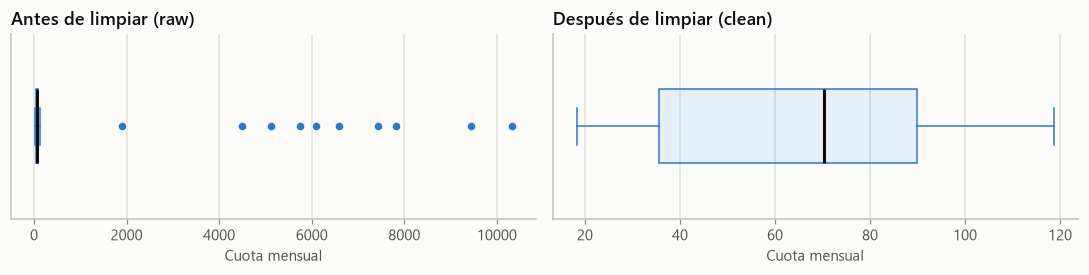

In [21]:
raw_charges = query(conn, "SELECT monthly_charges FROM raw_subscriptions WHERE monthly_charges IS NOT NULL")["monthly_charges"]
clean_charges = clean["subscriptions"]["monthly_charges"]

fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
panels = [(axes[0], raw_charges, "Antes de limpiar (raw)"), (axes[1], clean_charges, "Después de limpiar (clean)")]
for ax, values, title in panels:
    ax.boxplot(
        values,
        orientation="horizontal",
        widths=0.4,
        patch_artist=True,
        boxprops={"facecolor": viz.BLUE_WASH, "edgecolor": viz.BLUE},
        medianprops={"color": viz.INK, "linewidth": 2},
        whiskerprops={"color": viz.BLUE},
        capprops={"color": viz.BLUE},
        flierprops={"marker": "o", "markersize": 6, "markerfacecolor": viz.BLUE, "markeredgecolor": viz.SURFACE},
    )
    ax.set_title(title)
    ax.set_xlabel("Cuota mensual")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save_figure(fig, "01_monthly_charges_before_after_cleaning")
plt.show()

**Lectura:** antes de limpiar, los 10 errores de coma decimal aplastan la escala y la distribución real queda reducida a una franja estrecha a la izquierda. Después, la cuota va de 18 a 119, sin valores fuera de los bigotes. (Cada panel tiene su propia escala horizontal: son dos gráficos separados a propósito.)

### 7.2 ¿Quedan outliers en los datos limpios?

In [22]:
subscriptions = clean["subscriptions"].assign(tenure=months_between(clean["subscriptions"]["start_date"], config.SNAPSHOT_DATE))

rows = []
for column in ["tenure", "monthly_charges", "total_charges"]:
    values = subscriptions[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "variable": column, "Q1": q1, "Q3": q3, "límite inferior": lower, "límite superior": upper,
        "outliers": int(((values < lower) | (values > upper)).sum()), "asimetría (skew)": values.skew(),
    })
pd.DataFrame(rows).round(2)

,variable,Q1,Q3,límite inferior,límite superior,outliers,asimetría (skew)
0,tenure,9.00,55.00,-60.00,124.00,0,0.24
1,monthly_charges,35.50,89.85,-46.02,171.38,0,-0.22
2,total_charges,398.55,3786.60,-4683.52,8868.67,0,0.96


**Lectura:** con la regla IQR **no queda ningún outlier** en antigüedad, cuota ni total facturado. `total_charges` es asimétrica a la derecha (*skew* ≈ 0,96): muchos clientes con poco acumulado y pocos con mucho. Eso es una forma de la distribución, no un error. **No eliminamos nada.**

### 7.3 Sesgos: la distribución de la antigüedad

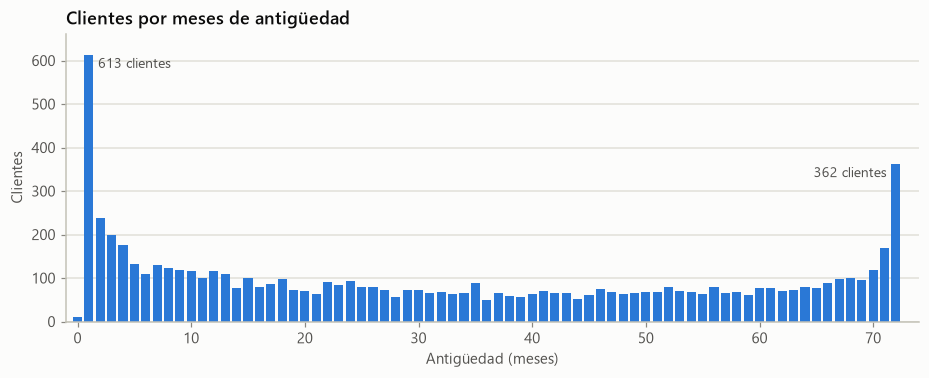

tenure,68,69,70,71,72
clientes,100,95,119,170,362


In [23]:
tenure_counts = subscriptions["tenure"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(tenure_counts.index, tenure_counts.values, width=0.8, color=viz.BLUE)
for month, side, offset in [(1, "left", 6), (72, "right", -6)]:  # etiqueta al lado de la barra, sin tocar el eje
    ax.annotate(f"{tenure_counts[month]} clientes", xy=(month, tenure_counts[month]), xytext=(offset, -2),
                textcoords="offset points", ha=side, va="top", fontsize=9, color=viz.INK_SECONDARY)
ax.set_ylim(0, tenure_counts.max() * 1.08)
ax.set_title("Clientes por meses de antigüedad")
ax.set_xlabel("Antigüedad (meses)")
ax.set_ylabel("Clientes")
ax.set_xlim(-1, 74)
ax.grid(axis="x", visible=False)
viz.save_figure(fig, "01_tenure_distribution")
plt.show()

tenure_counts.loc[68:72].rename("clientes").to_frame().T

**Lectura:** hay dos acumulaciones.

- **En 72 meses hay 362 clientes**, más del doble que en 71 (170). La variable termina justo en 72 (6 años). Lo más probable es que **72 signifique "72 o más"**, un tope o *censura* de la variable. Consecuencia: para los clientes más antiguos no conocemos su antigüedad real, y cualquier efecto de la antigüedad se aplana en ese extremo. No lo modificamos, pero lo documentamos como limitación.
- **En 1 mes hay 613 clientes**, muchas altas recientes. No es un error, pero importa para la hipótesis H4 (clientes nuevos).

**Sesgo de supervivencia:** la foto solo incluye a quienes seguían siendo clientes al empezar el último mes. Los que se fueron antes no aparecen. Por eso los clientes antiguos son, por definición, "supervivientes", y hay que tenerlo presente al interpretar cualquier relación entre antigüedad y churn.

## 8. Verificación final

Volvemos a ejecutar **las mismas reglas SQL** sobre la capa limpia y comprobamos que no hemos alterado la variable objetivo.

In [24]:
display(quality_summary(run_quality_checks(conn, layer="clean")).set_index("check").T)

churn_rate_source = (source["Churn"] == "Yes").mean()
churn_rate_clean = clean["subscriptions"]["end_date"].notna().mean()
print(f"Clientes: {len(clean['customers']):,} · Pagos: {len(clean['payments']):,}")
print(f"Tasa de churn en el CSV original: {churn_rate_source:.2%} · tras la limpieza: {churn_rate_clean:.2%}")

check,check_duplicate_customers,check_duplicate_subscriptions,check_duplicate_payments,check_conflicting_payments,check_missing_values,check_non_canonical_categories,check_impossible_values,check_monthly_charges_outliers,check_orphan_payments,check_unmatched_records,check_payments_outside_subscription,check_inconsistent_dates,check_billing_reconciliation,check_monthly_charge_vs_last_payment
rows_flagged,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Clientes: 7,043 · Pagos: 227,990
Tasa de churn en el CSV original: 26.54% · tras la limpieza: 26.54%


**Lectura:** las 14 comprobaciones devuelven 0 filas sobre la capa limpia. Quedan 7.043 clientes y 227.990 pagos, y la tasa de churn es idéntica antes y después (26,54 %): **la limpieza no ha sesgado la variable objetivo**. Además, un test automático (`tests/test_data_pipeline.py`) comprueba que las tablas limpias reconstruyen exactamente el CSV original.

## 9. Resumen

| Aspecto | Resultado |
|---|---|
| Dataset | 7.043 clientes, 21 variables, sin duplicados en origen |
| Problemas reales del CSV | 11 `TotalCharges` vacíos (clientes sin facturar), `TotalCharges` leído como texto, formato 0/1 frente a Yes/No, categorías redundantes, posible tope de `tenure` en 72 |
| Defectos inyectados detectados con SQL | 200 de 200: duplicados, nulos, etiquetas, extremos, huérfanos y fechas imposibles |
| Filas eliminadas | Solo copias exactas (20 clientes, 50 pagos) y pagos imposibles de atribuir o fechar (40). Ningún cliente real perdido |
| Valores corregidos | 70 etiquetas, 20 cuotas (recuperadas de facturación) y 11 totales (0 estructural) |
| Outliers reales | Ninguno según IQR. `total_charges` es asimétrica, no anómala |
| Sesgos a recordar | Tope de `tenure` en 72 y sesgo de supervivencia en la foto |

**Siguiente paso:** con las tablas limpias, `sql/02_customer_features.sql` construye la tabla final de una fila por cliente.

In [25]:
conn.close()